In [ ]:
import sys
import yaml
import numpy as np
import pandas as pd
from pathlib import Path

sys.path.append("../..")
from src.solvers.gurobi import solve_wflo_gurobi
from src.solvers.utils import save_benchmark_layout
from src.qubo_windfarm_layout.evaluation import load_layout_coordinates, layouts_folder_to_df
from src.qubo_windfarm_layout.visualization import plot_gurobi_refinement, plot_selected_layout
from src.qubo_windfarm_layout.model import build_local_candidates, get_warmstart, get_farm_area, build_local_wake_loss_matrix_optimized


Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2864483
WLS license 2864483 - registered to Accenture GmbH (Germany)


# Strategies
Faccio una prima run grezza con risoluzione tale che ho invalid pairs non nulle e wake loss migliori della baseline.
Ho scelto GRID_RESOLUTION = 128m e TIMEOUT = 30m

Faccio run con GRID_RESOLUTION che va come potenza di due (64 -> 32 -> 16 -> 8) e raggio uguale a 2*GRID_RESOLUTION, TIMEOUT di 30m


In [ ]:
# Variables
GRID_RESOLUTION = 2
TIMEOUT = 10 # 60 * 30
SOLVER = "gurobi_miqp"
STARTING_LAYOUT = f"../../results/layouts/{SOLVER}/gurobi_local_4m_1800s_warmstart.yaml"

# Parameters
RADIUS = 2*GRID_RESOLUTION
WAKE_LOSS_PATH = f"../../results/precomputed/{SOLVER}/wake_loss_{SOLVER}_res_{GRID_RESOLUTION}m_rad_{RADIUS}.npz"

(777, 2)
(3579, 2)


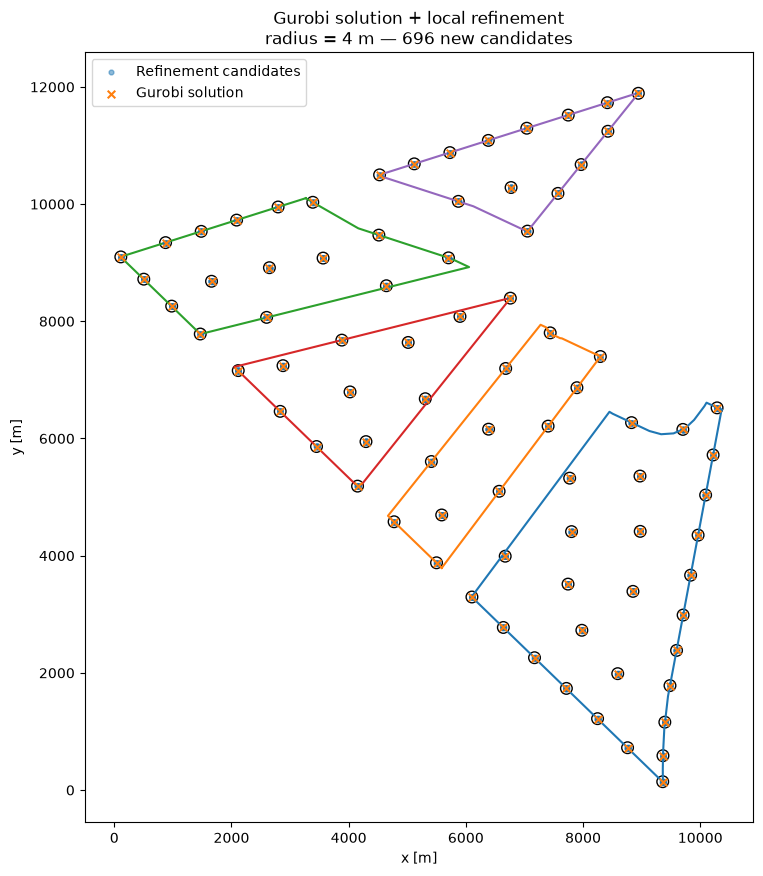

In [3]:
gurobi_positions = load_layout_coordinates(STARTING_LAYOUT)

_, farm_area = get_farm_area()

candidate_locations, invalid_pairs = build_local_candidates(
    gurobi_positions=gurobi_positions,
    farm_area=farm_area,
    radius_m=RADIUS,
    step_m=GRID_RESOLUTION,
)

print(candidate_locations.shape)
print(invalid_pairs.shape)

plot_gurobi_refinement(
    gurobi_positions=gurobi_positions,
    candidate_locations=candidate_locations,
    radius_m=RADIUS,
)

In [4]:
# wake_loss_matrix, A0 = build_local_wake_loss_matrix_optimized(
#     candidate_locations,
#     output_path=WAKE_LOSS_PATH
# )

wake_loss_matrix = np.load(WAKE_LOSS_PATH)["wake_loss_matrix"]

warm_start = get_warmstart(candidate_locations=candidate_locations, starting_layout=STARTING_LAYOUT)

Set parameter OutputFlag to value 1
Set parameter MIPGap to value 0.01
Set parameter NonConvex to value 2
Set parameter Threads to value 1
Set parameter NodefileStart to value 0.5
Set parameter NodefileDir to value "/tmp"
Set parameter SoftMemLimit to value 28
Set parameter MIPFocus to value 0
Set parameter TimeLimit to value 10
RAM before model.optimize()
System available : 11.74 GB
System used      : 23.5%
Python process   : 0.19 GB
RAM after model.optimize()
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.1 LTS")

CPU model: Intel(R) Core(TM) Ultra 7 265H, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 1 threads

Non-default parameters:
TimeLimit  10
SoftMemLimit  28
MIPGap  0.01
NodefileStart  0.5
NonConvex  2
Threads  1

WLS license 2864483 - registered to Accenture GmbH (Germany)
Optimize a model with 3580 rows, 777 columns and 7935 nonzeros (Min)
Model fingerprint: 0xa0b7f1cd
Model has 0 linear object

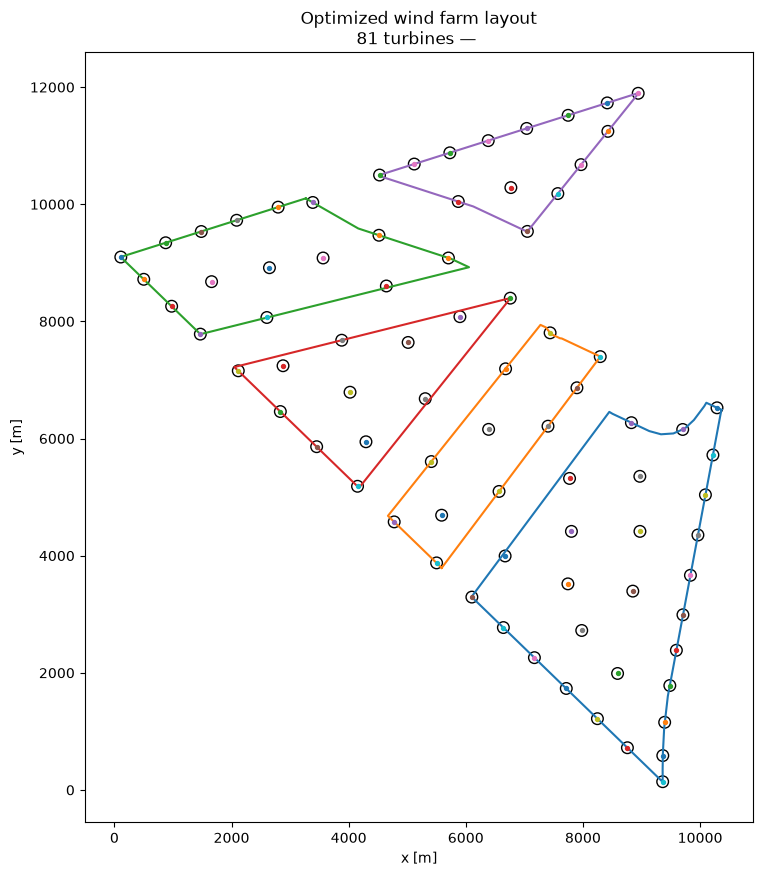

Layout saved to: /home/maicolnicolini/code/qubo-wind-farm-layout/notebooks/gurobi/../../results/layouts/gurobi/gurobi_local_2m_10s_warmstart.yaml
H_QUBO: 834246.0479297923
AEP: 2901.665231 GWh


PosixPath('/home/maicolnicolini/code/qubo-wind-farm-layout/notebooks/gurobi/../../results/layouts/gurobi/gurobi_local_2m_10s_warmstart.yaml')

In [5]:
result = solve_wflo_gurobi(
    wake_loss_matrix=wake_loss_matrix,
    invalid_pairs=invalid_pairs,
    n_turbines=81,
    warm_start=warm_start,
    time_limit=TIMEOUT,
    mip_gap=0.01,
    mip_focus=0,
)

print("Objective:", result["objective"])
print("Runtime:", result["runtime"])
print("MIP gap:", result["mip_gap"])
print("Best bound:", result["best_bound"])
print("N turbines:", result["z"].sum())

selected_indices = result["selected_indices"]
selected_locations_gurobi = candidate_locations[
    selected_indices
]

plot_selected_layout(selected_locations=selected_locations_gurobi)


save_benchmark_layout(
    selected_locations=selected_locations_gurobi,
    solver_name="gurobi",
    output_dir=f"results/layouts/gurobi",
    filename=f"gurobi_local_{GRID_RESOLUTION}m_{TIMEOUT}s_warmstart.yaml",
    grid_resolution=GRID_RESOLUTION,
    time_limit_s=TIMEOUT,
    candidate_locations=candidate_locations,
    wake_loss_matrix=wake_loss_matrix,
)

In [ ]:
df = layouts_folder_to_df(
    "../../results/layouts/gurobi_miqp"
)

df.sort_values(by="h_qubo", ascending=True)

,file,solver,grid_resolution,n_turbines,time_limit_s,h_qubo,aep_gwh,wake_loss_pct,min_distance_m,valid_cardinality,valid_spacing,valid_boundary,valid
5,gurobi_local_2m_1800s_warmstart.yaml,gurobi,2,81,1800.0,834165.660350,2901.707989,NaN,NaN,NaN,NaN,NaN,NaN
4,gurobi_local_2m_10s_warmstart.yaml,gurobi,2,81,10.0,834246.047930,2901.665231,NaN,NaN,NaN,NaN,NaN,NaN
7,gurobi_local_4m_1800s_warmstart.yaml,gurobi,4,81,1800.0,834516.303123,2901.480912,15.814563,444.018018,True,True,True,True
9,gurobi_local_8m_1800s_warmstart.yaml,gurobi,8,81,1800.0,835138.437035,2901.043028,15.827268,440.072721,True,True,True,True
3,gurobi_local_16m_1800s_warmstart.yaml,gurobi,16,81,1800.0,836292.426254,2900.314748,15.848399,432.000000,True,True,True,True
6,gurobi_local_32m_1800s_warmstart.yaml,gurobi,32,81,1800.0,839624.502466,2897.871087,15.919301,448.000000,True,True,True,True
8,gurobi_local_64m_1800s_warmstart.yaml,gurobi,64,81,1800.0,846556.909719,2892.777997,16.067075,448.000000,True,True,True,True
2,gurobi_local_128m_1800s_warmstart.yaml,gurobi,128,81,1800.0,859716.846568,2883.058938,16.349070,512.000000,True,True,True,True
1,gurobi_local_128_5s_warmstart.yaml,gurobi,128,81,3600.0,860132.979802,2882.654110,16.360816,512.000000,True,True,True,True
0,gurobi_128_3600s.yaml,gurobi,128,81,NaN,NaN,2882.550595,16.363820,512.000000,True,True,True,True
